In [8]:
import pandas as pd
from rapidfuzz import fuzz
from collections import defaultdict
import json
from pathlib import Path
from tqdm.cli import tqdm
from matplotlib import pyplot as plt
import seaborn as sns

In [9]:
from sys import path as sys_path
project_root = Path.cwd().parent.parent
if project_root not in sys_path:
    sys_path.append(str(project_root))

In [10]:
from src.duplicate_page_discovery import DuplicateConfig
from src.book_overlap_visualizations import (
    migration_duplicate_filtering_before_after_counts,
    plot_book_year_event_heatmap,
    plot_migration_similarity_heatmaps,
    plot_non_duplicate_migration_histogram,
)

In [11]:
data_dir = project_root/"data/"
outputs_dir = project_root/"outputs/"

## Examining specific years from a parish

{'tampereen_tuomiokirkkoseurakunta_muuttaneet_1812-1840_ap': {'before': 1923,
  'after': 1923},
 'tampereen_tuomiokirkkoseurakunta_muuttaneet_1812-1840_tk636': {'before': 1639,
  'after': 587}}

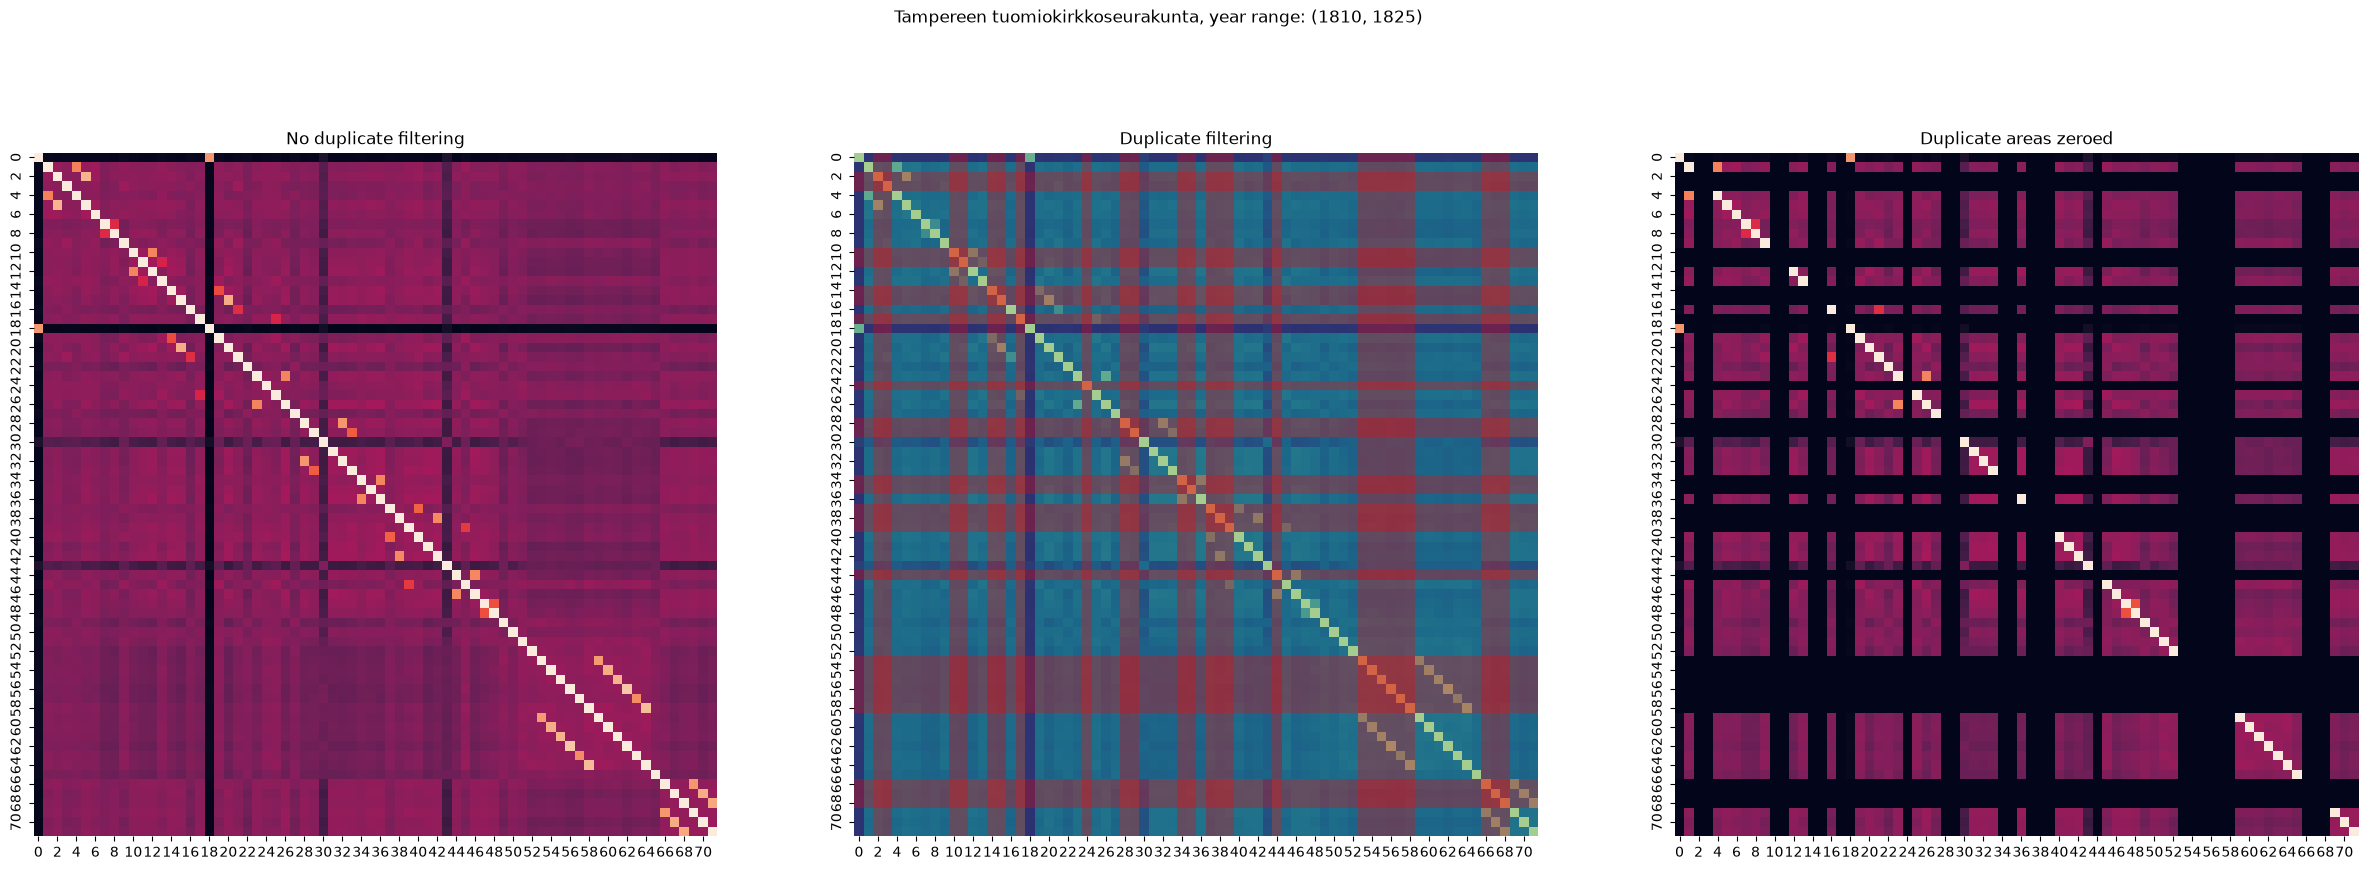

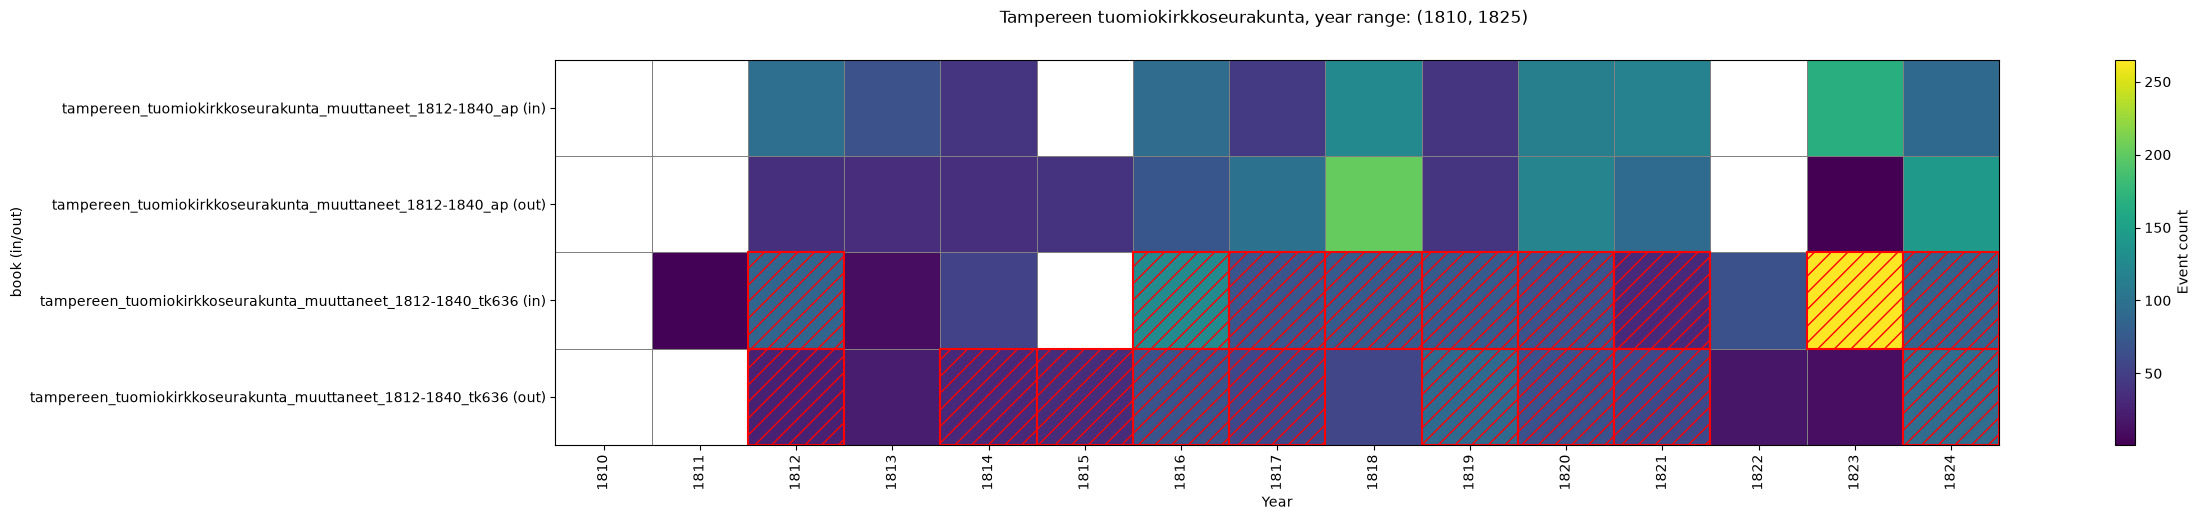

In [12]:
df_tampereen_tuom = pd.read_json(
    outputs_dir/f"json/all_migration_events_parish_splits_duplicate_info/543_migration_events.jsonl",
    lines=True,
)
fig, axs = plot_migration_similarity_heatmaps(
    df_tampereen_tuom,
    "Tampereen tuomiokirkkoseurakunta",
    (1810, 1825),
    scorer=fuzz.ratio,
    vmax=100.0,
)
fig, axs = plot_book_year_event_heatmap(
    df_tampereen_tuom, "Tampereen tuomiokirkkoseurakunta", (1810, 1825)
)
migration_duplicate_filtering_before_after_counts(
    df_tampereen_tuom, (1810, 1825)
)

## Examining whole history of a parish

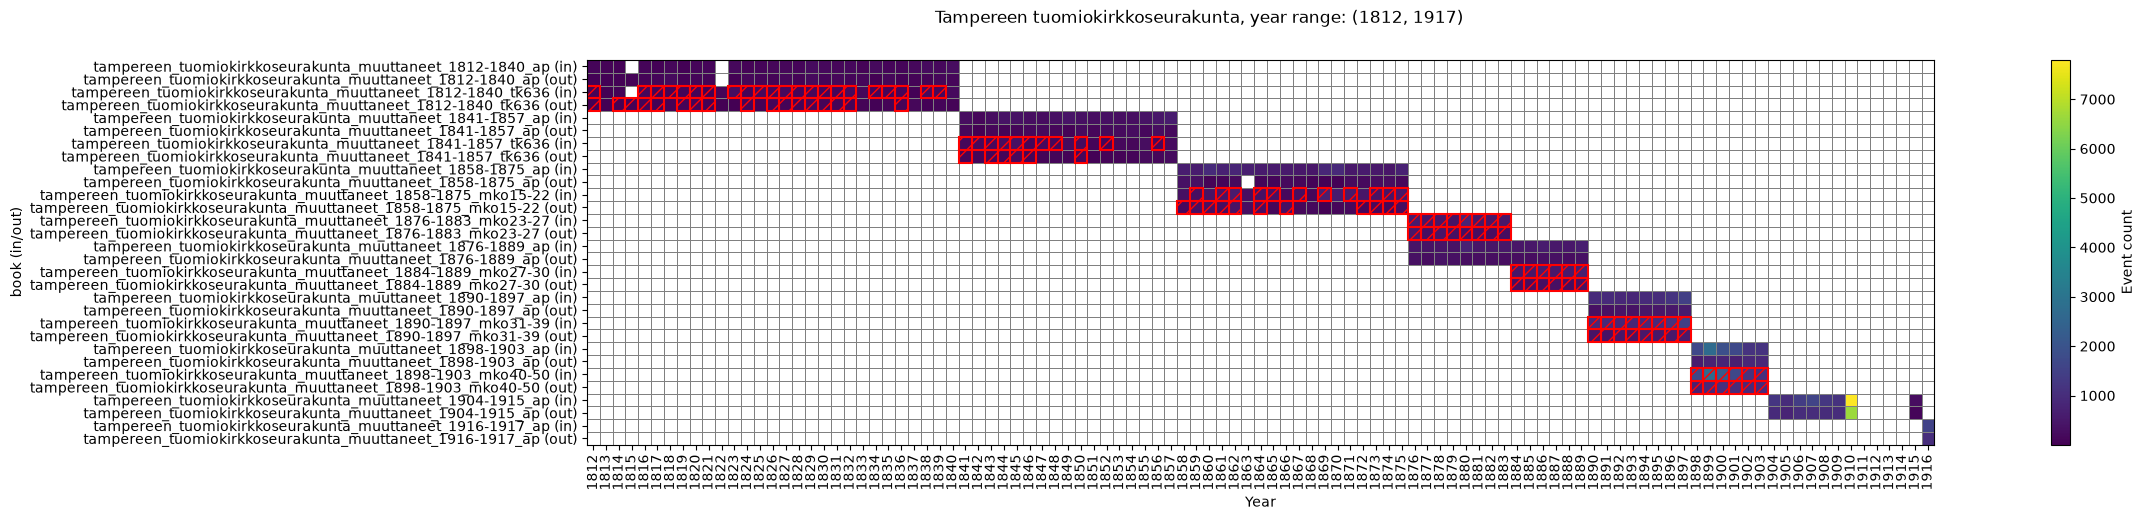

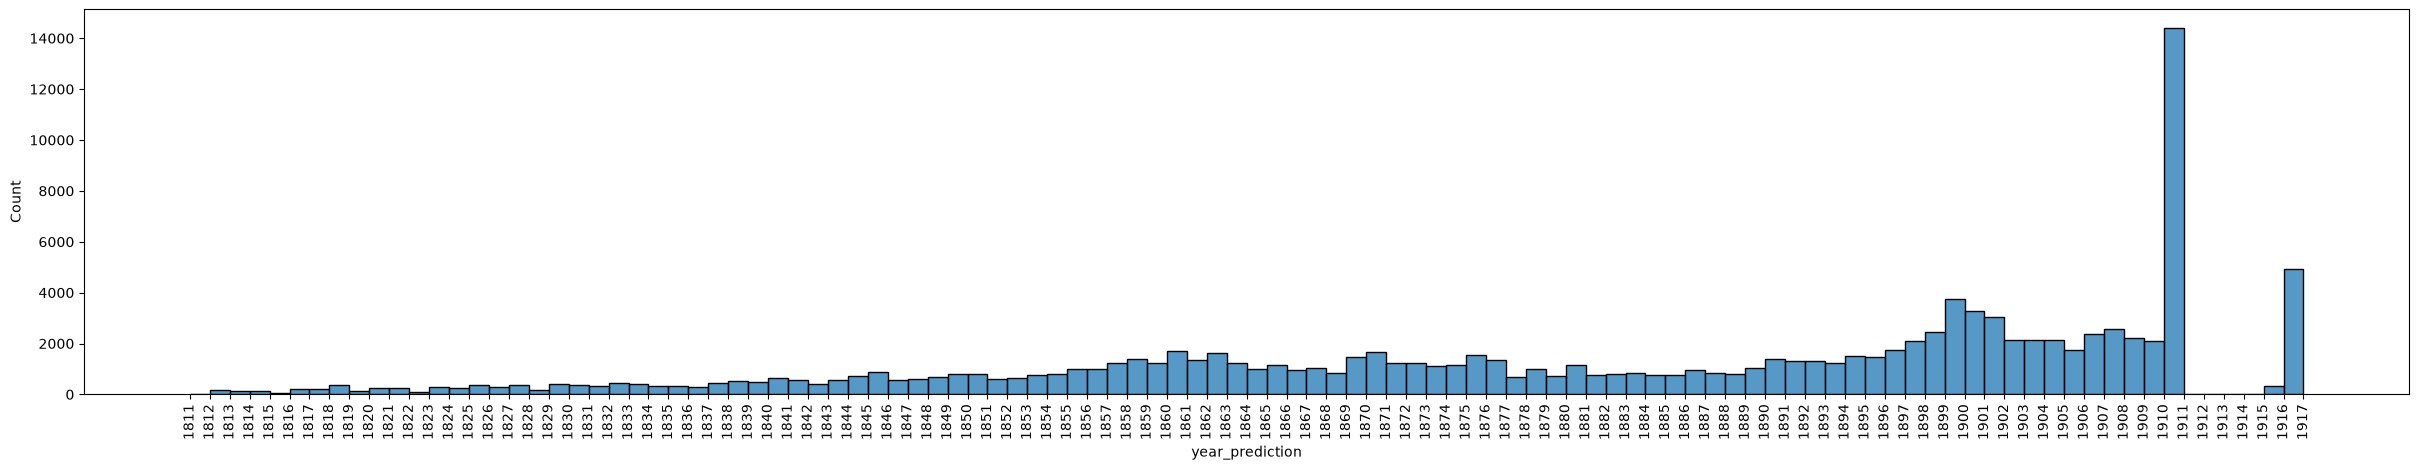

In [13]:
fig, axs = plot_book_year_event_heatmap(df_tampereen_tuom, "Tampereen tuomiokirkkoseurakunta", (1812, 1917))
plot_non_duplicate_migration_histogram(df_tampereen_tuom)

## Overall counts of events

In [14]:
total_all_events = 0
total_all_events_no_empty_row = 0
total_non_duplicate_events = 0
total_non_duplicate_events_clear_direction = 0
total_non_duplicate_events_no_empty_row = 0
total_non_duplicate_events_clear_direction_no_empty_row = 0

non_duplicate_events_year_counts = defaultdict(int)
non_duplicate_events_year_counts_clear_direction = defaultdict(int)
non_duplicate_events_year_counts_no_empty_row = defaultdict(int)
non_duplicate_events_year_counts_clear_direction_no_empty_row = defaultdict(int)

output_jsonls = list(Path(
    outputs_dir/"json/all_migration_events_parish_splits_duplicate_info"
).glob("*.jsonl"))
for file_path in tqdm(output_jsonls):
    with open(file_path, "r") as fp:
        for line in fp:
            e = json.loads(line)
            total_all_events += 1
            empty_row = True
            if e["has_information"]:
                empty_row = False
                total_all_events_no_empty_row += 1

            if (
                e["duplicate"] == False
                and ((e["in/out"] == "in") or (e["in/out"] == "out"))
                and (e["year_prediction"] in range(
                    *DuplicateConfig.valid_year_prediction_bounds
                ))
            ):
                total_non_duplicate_events += 1
                total_non_duplicate_events_clear_direction += 1
                non_duplicate_events_year_counts_clear_direction[e["year_prediction"]] += 1
                non_duplicate_events_year_counts[e["year_prediction"]] += 1

                if not empty_row:
                    total_non_duplicate_events_no_empty_row += 1
                    non_duplicate_events_year_counts_no_empty_row[e["year_prediction"]] += 1
                    total_non_duplicate_events_clear_direction_no_empty_row += 1
                    non_duplicate_events_year_counts_clear_direction_no_empty_row[e["year_prediction"]] += 1

            elif e["duplicate"] == False:
                total_non_duplicate_events += 1
                non_duplicate_events_year_counts[e["year_prediction"]] += 1
                if not empty_row:
                    total_non_duplicate_events_no_empty_row += 1
                    non_duplicate_events_year_counts_no_empty_row[e["year_prediction"]] += 1

non_duplicates_valid_year = {
    k: v for k, v in non_duplicate_events_year_counts.items() if k in range(
        *DuplicateConfig.valid_year_prediction_bounds
    )
}
non_duplicates_valid_year_no_empty_row = {
    k: v for k, v in non_duplicate_events_year_counts_no_empty_row.items() if k in range(
        *DuplicateConfig.valid_year_prediction_bounds
    )
}
non_duplicate_events_year_counts_valid_year_no_empty_row_clear_direction = {
    k: v for k, v in non_duplicate_events_year_counts_clear_direction_no_empty_row.items() if k in range(
        *DuplicateConfig.valid_year_prediction_bounds
    )

}

100%|██████████| 468/468 [00:39<00:00, 11.98it/s]


In [15]:
year_start = min(non_duplicates_valid_year.keys())
year_end = max(non_duplicates_valid_year.keys())

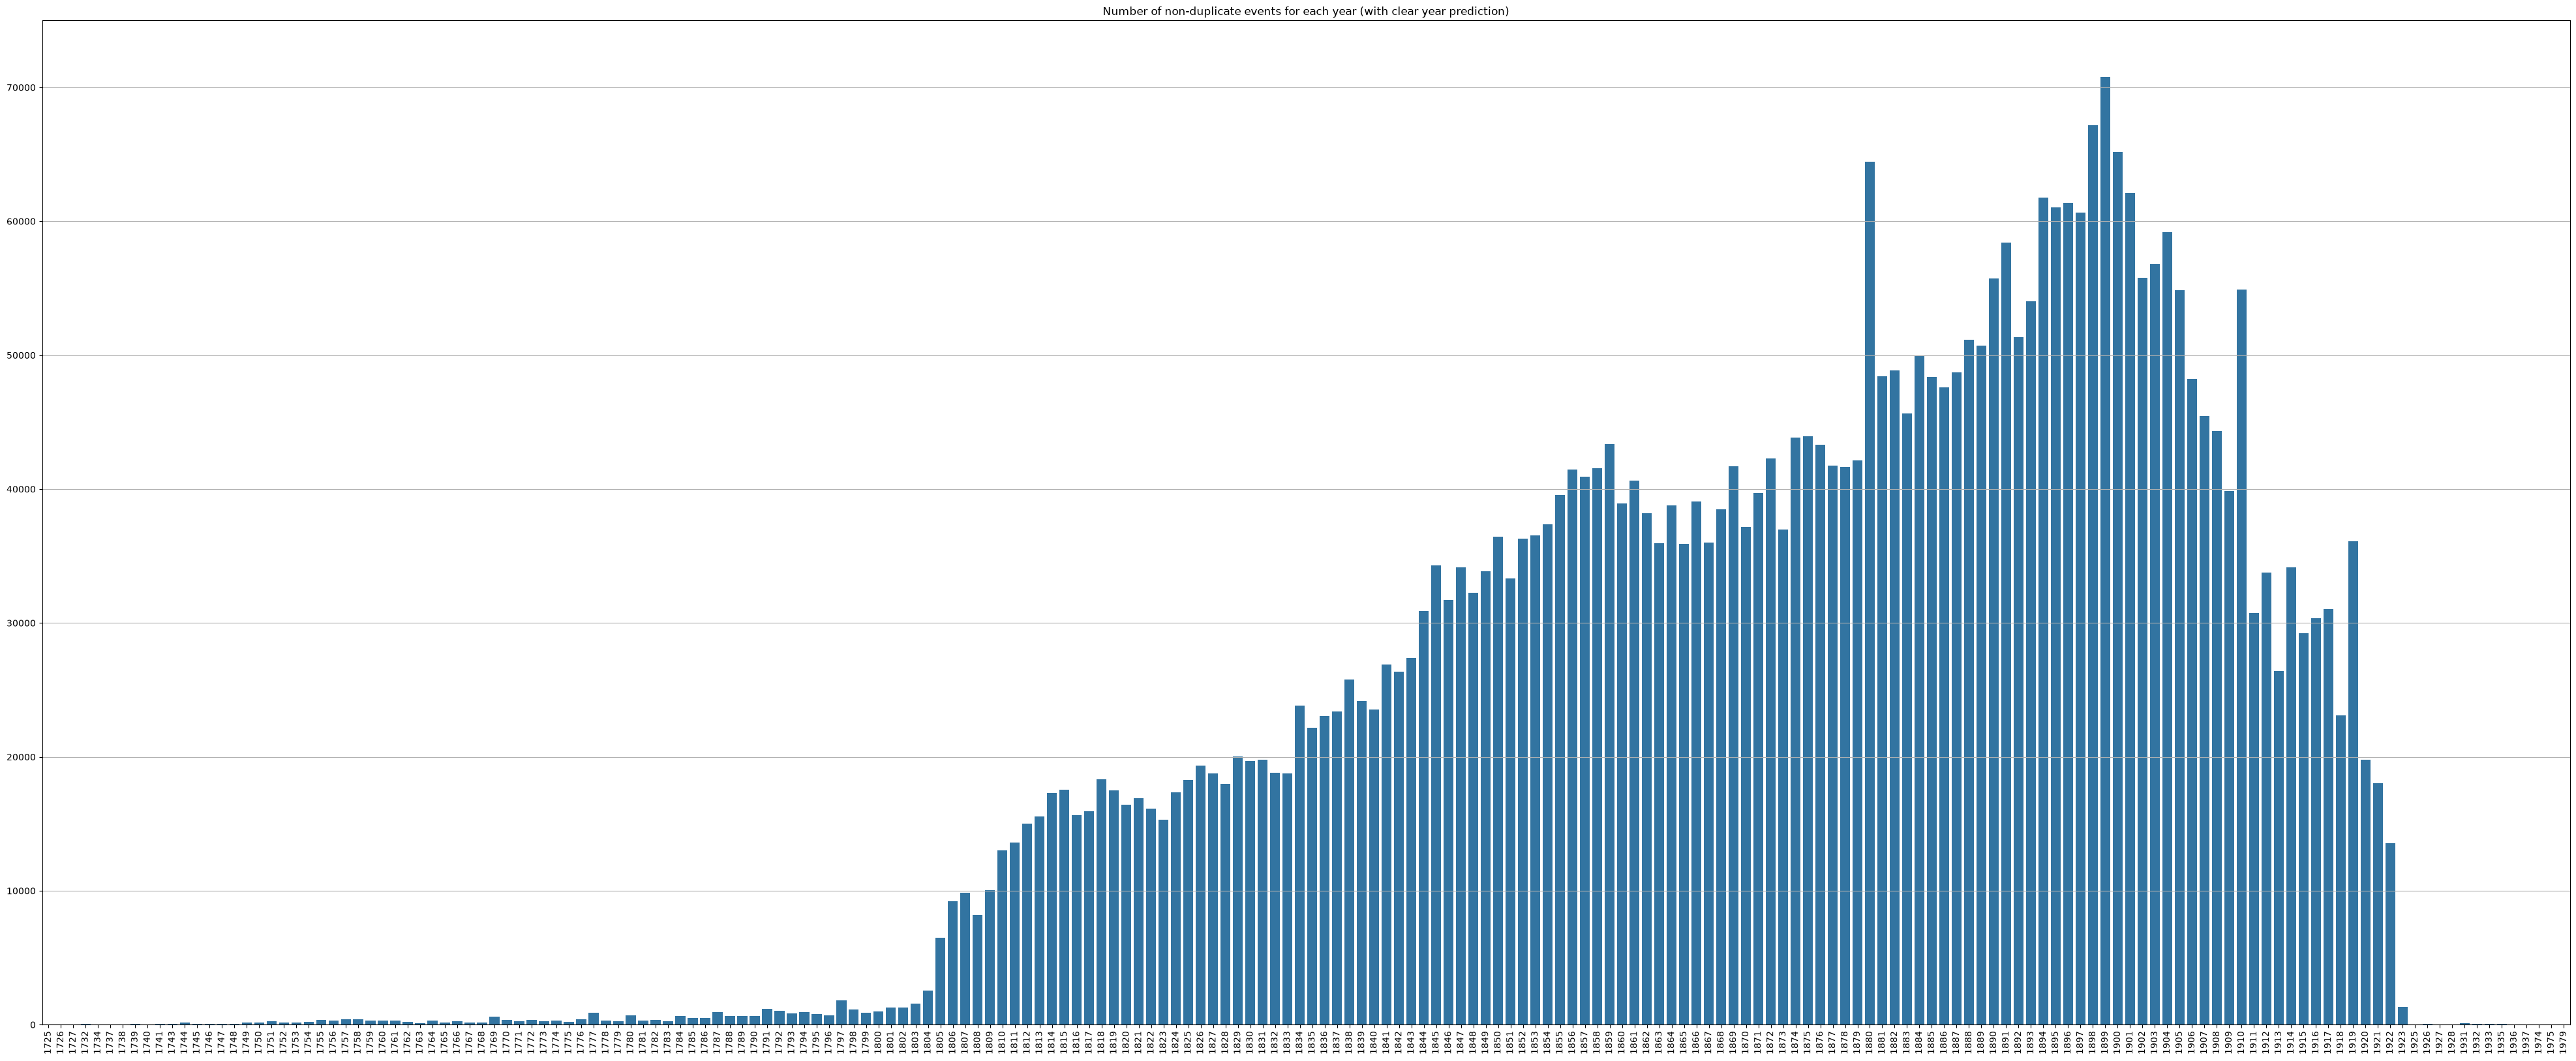

In [16]:
fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in non_duplicates_valid_year.items()]),
    y=tuple([x[1] for x in non_duplicates_valid_year.items()]),
)
axs.set_ylim(0, 75000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear year prediction)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(non_duplicates_valid_year.keys()), rotation=90)

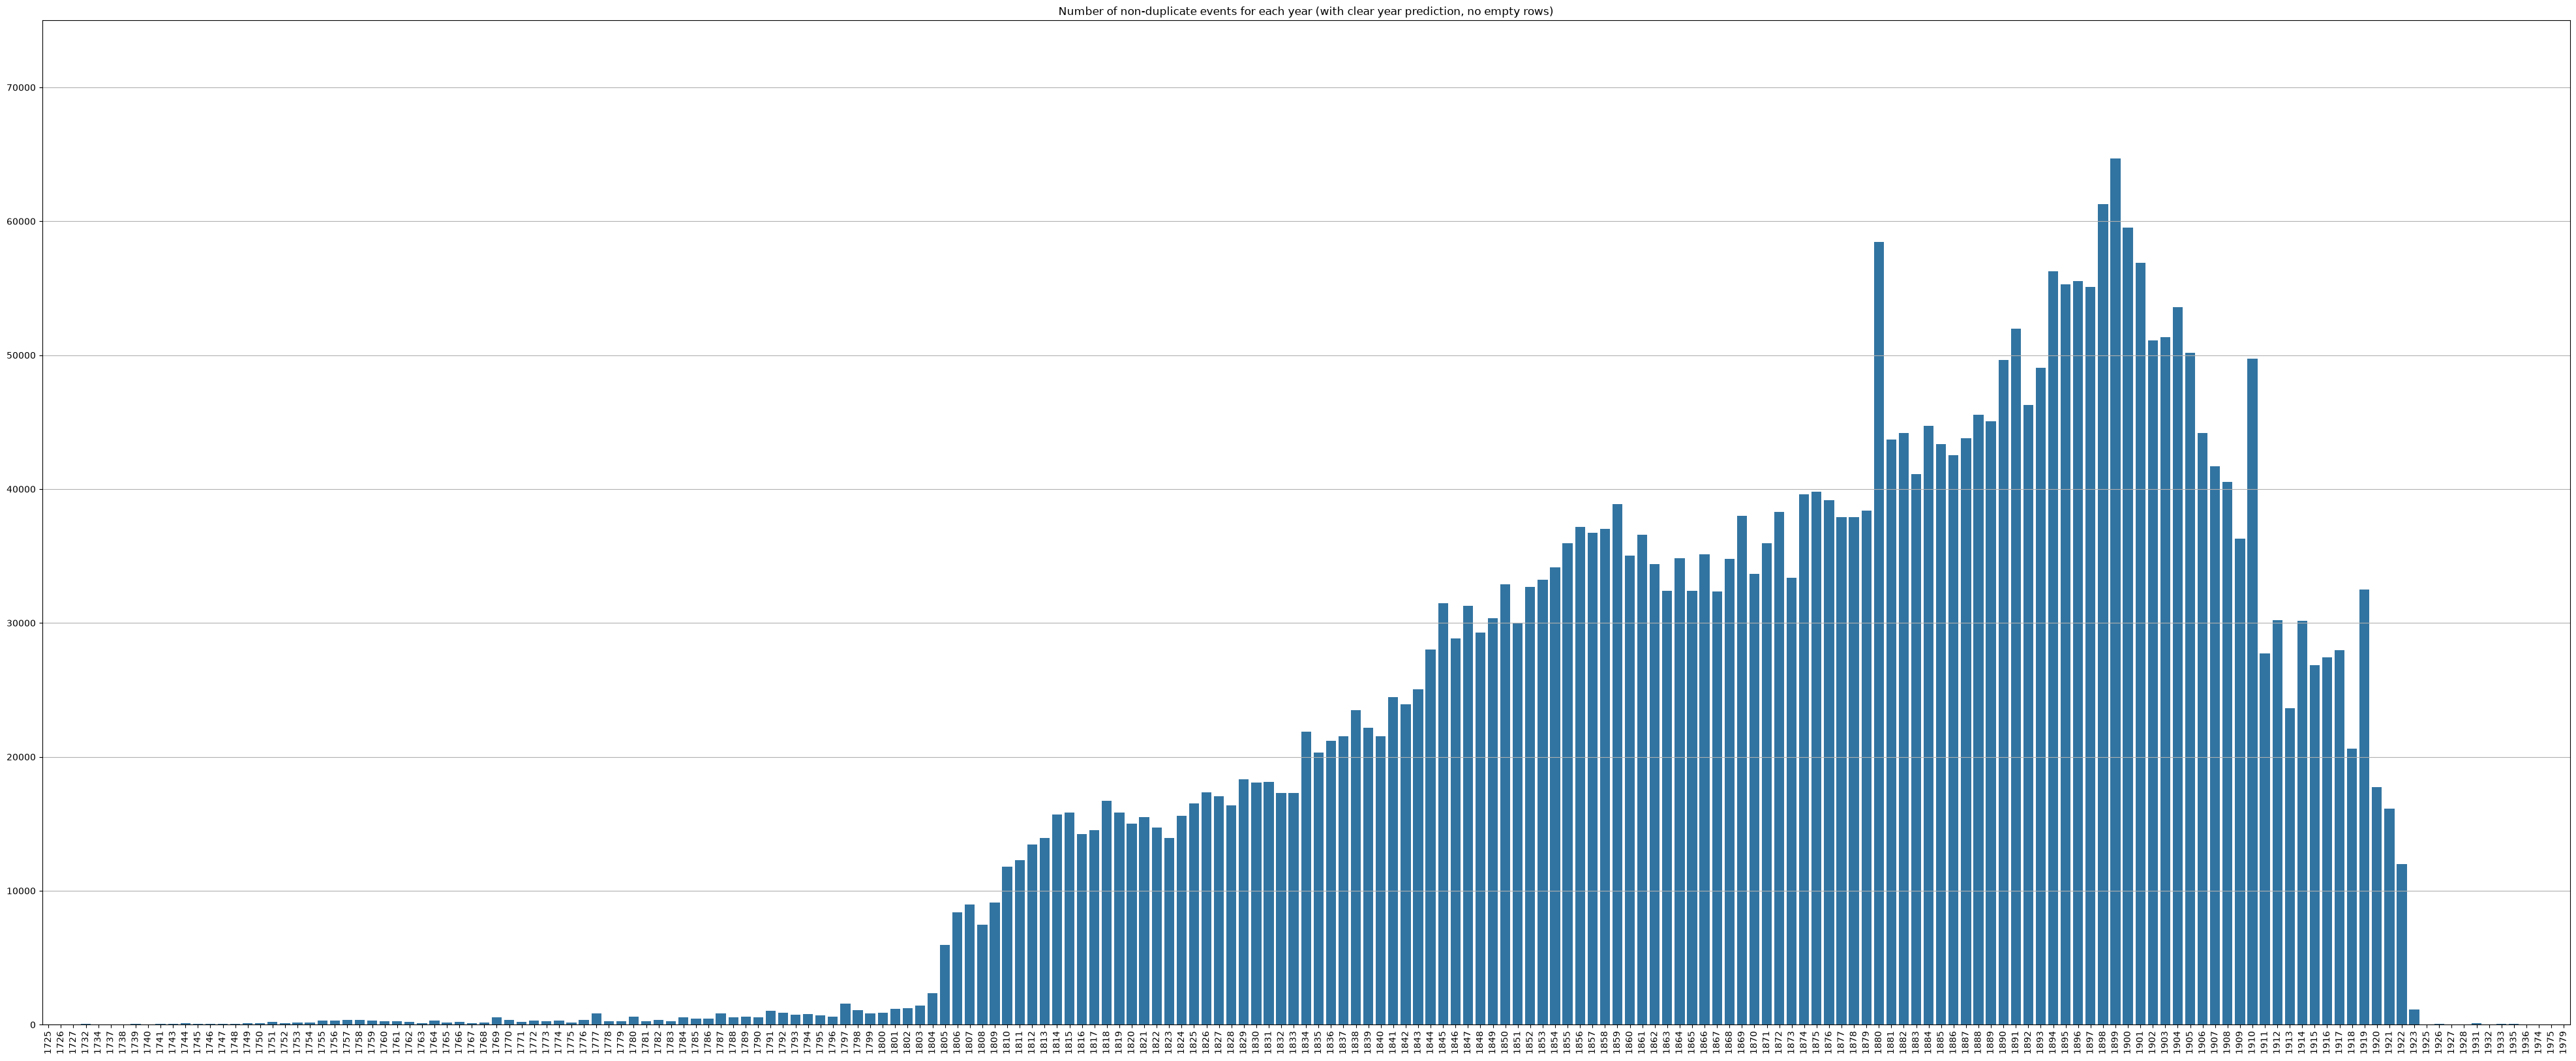

In [17]:
fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in non_duplicates_valid_year_no_empty_row.items()]),
    y=tuple([x[1] for x in non_duplicates_valid_year_no_empty_row.items()])
)
axs.set_ylim(0, 75000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear year prediction, no empty rows)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(non_duplicates_valid_year_no_empty_row.keys()), rotation=90)

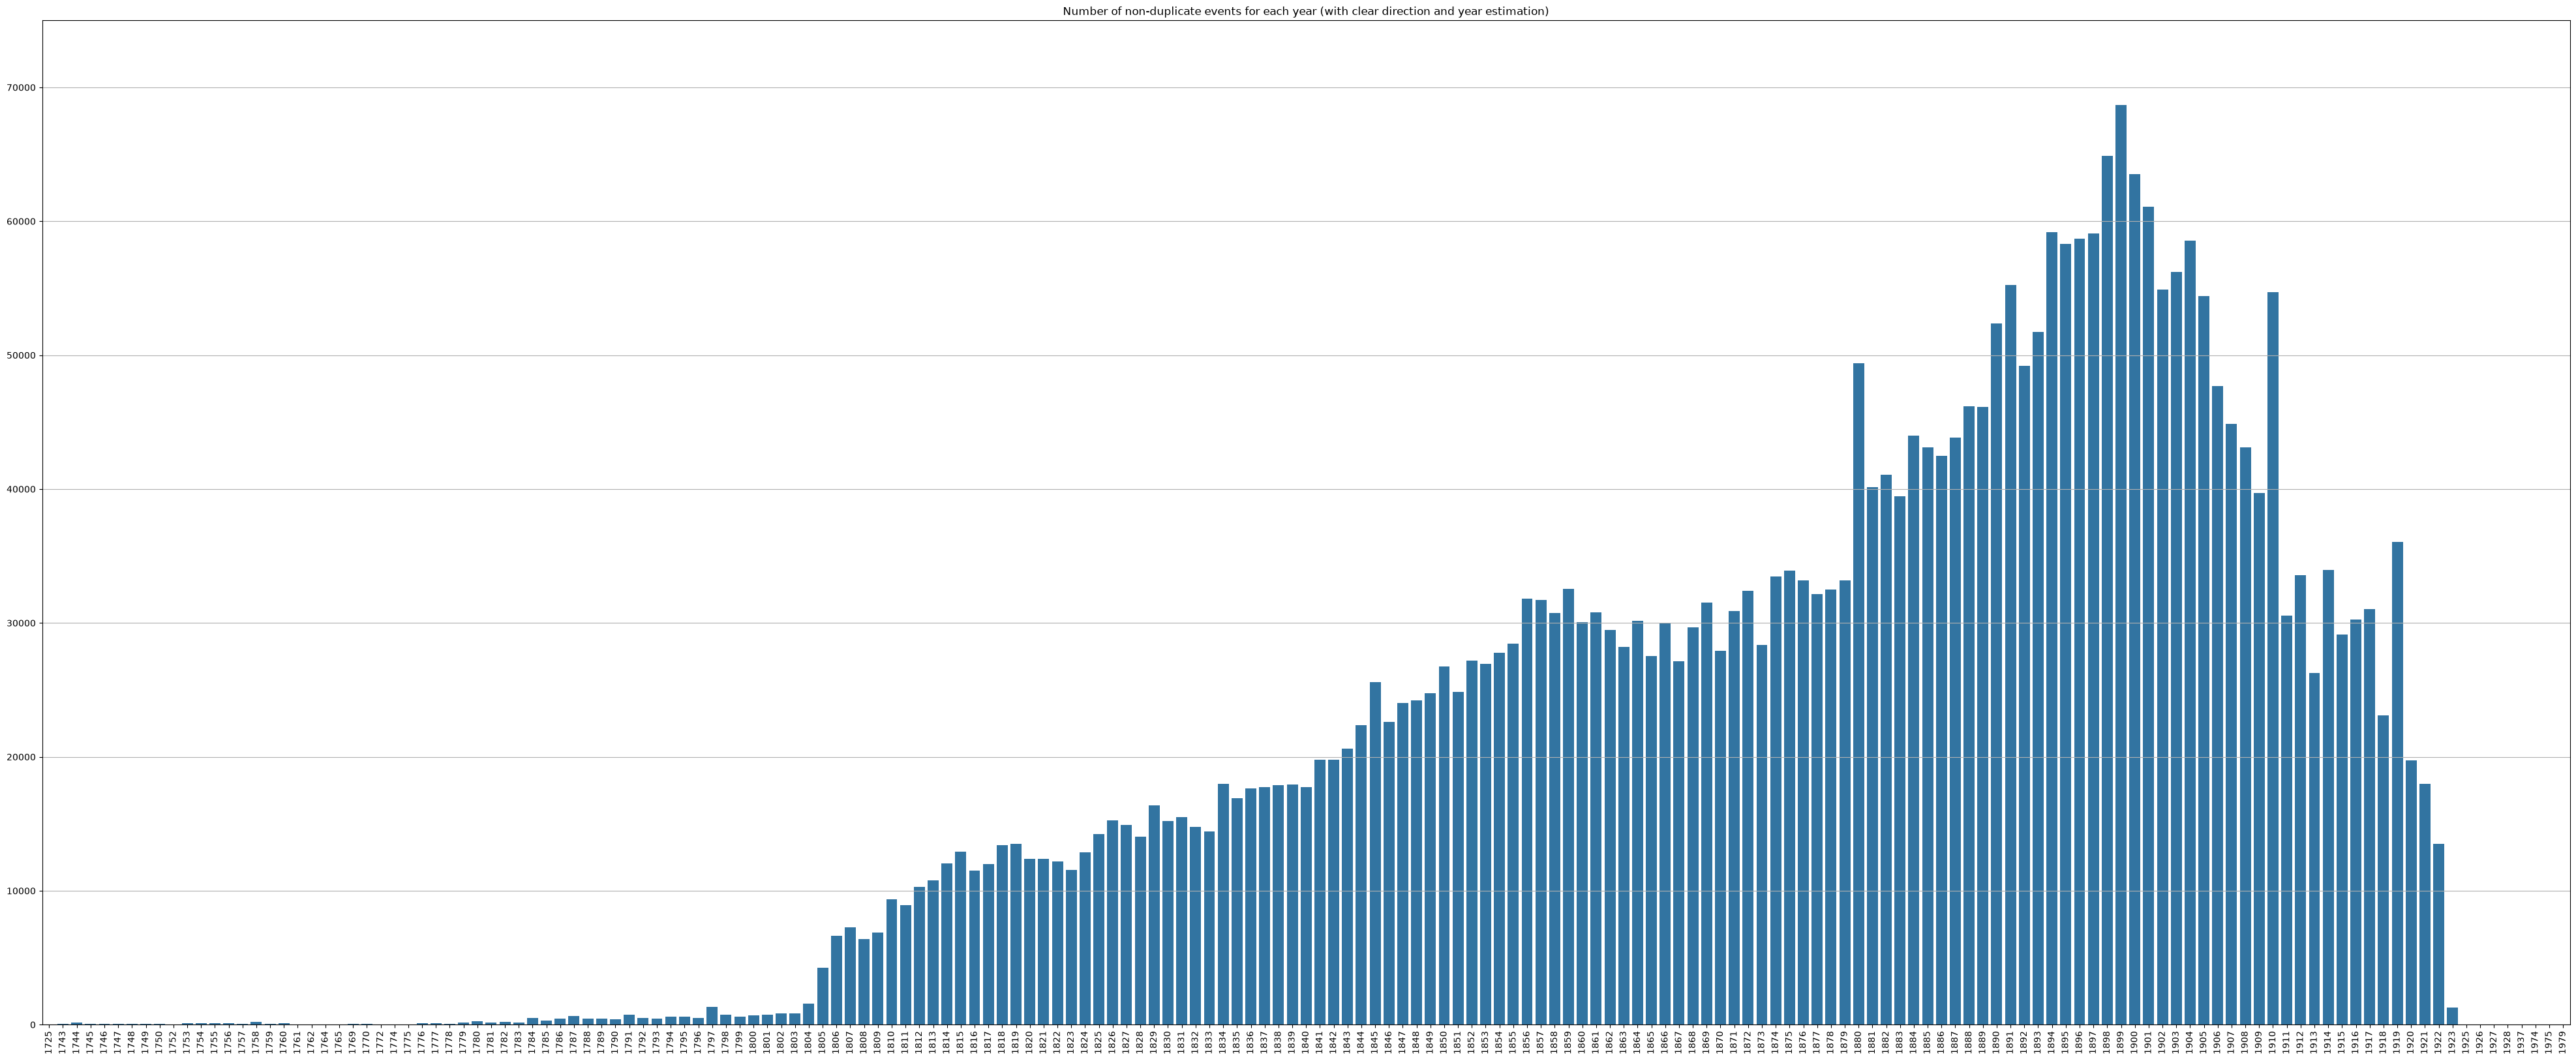

In [18]:
fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in non_duplicate_events_year_counts_clear_direction.items()]),
    y=tuple([x[1] for x in non_duplicate_events_year_counts_clear_direction.items()])
)
axs.set_ylim(0, 75000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear direction and year estimation)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(non_duplicate_events_year_counts_clear_direction.keys()), rotation=90)

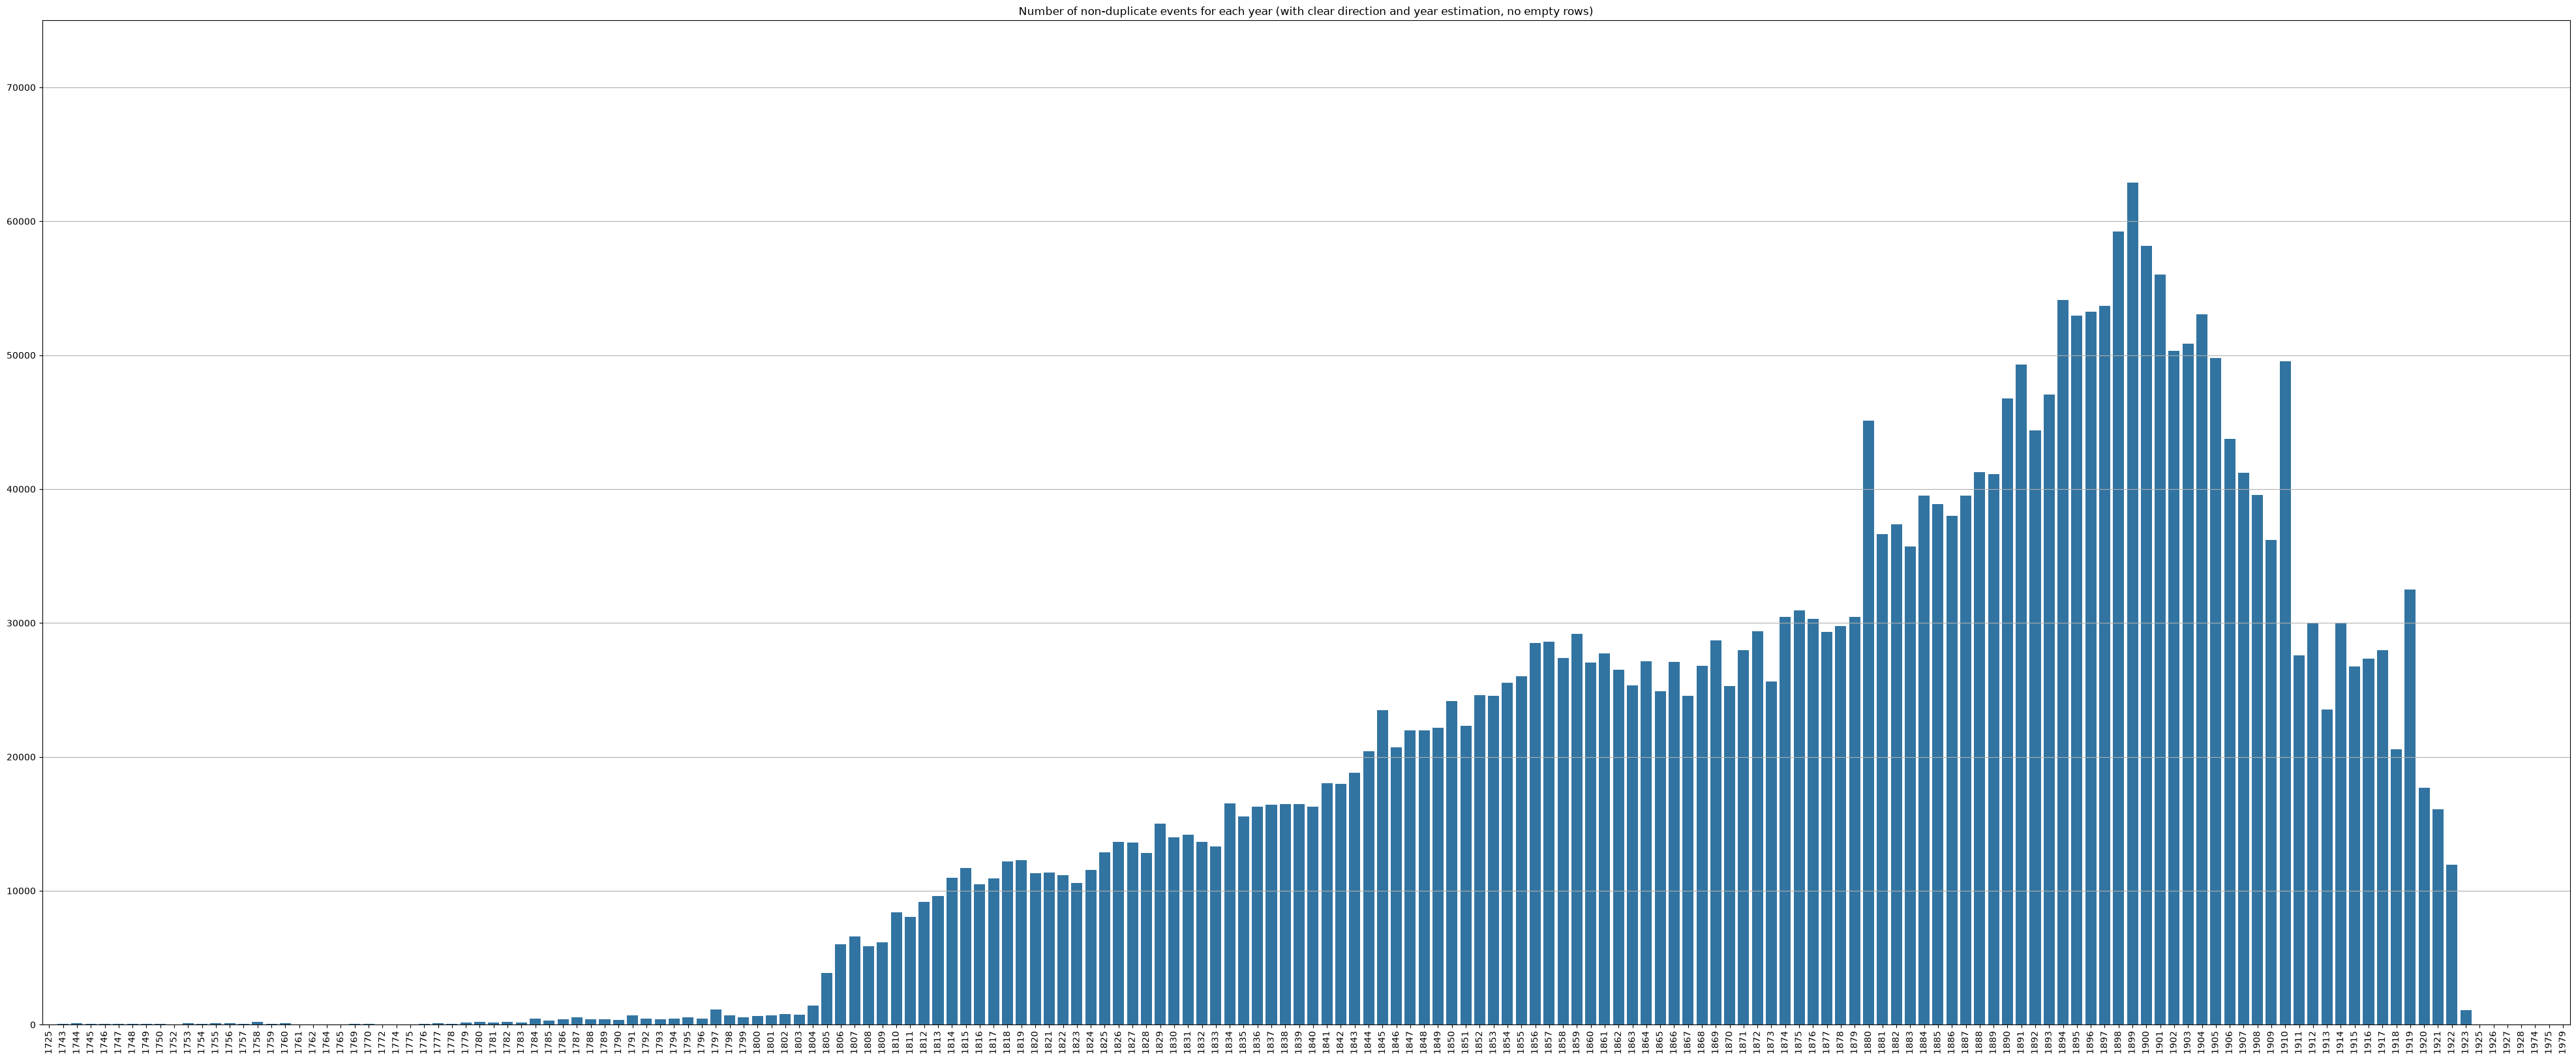

In [19]:
fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in non_duplicate_events_year_counts_valid_year_no_empty_row_clear_direction.items()]),
    y=tuple([x[1] for x in non_duplicate_events_year_counts_valid_year_no_empty_row_clear_direction.items()])
)
axs.set_ylim(0, 75000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear direction and year estimation, no empty rows)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(non_duplicate_events_year_counts_valid_year_no_empty_row_clear_direction.keys()), rotation=90)

In [20]:
print(
    f"Events in total: {total_all_events}",
    f"Rows with no data: {total_all_events - total_all_events_no_empty_row}",
    f"Total non-duplicate events: {total_non_duplicate_events}",
    f"At least {total_all_events - total_non_duplicate_events} duplicate events.",
    f"Total non-duplicate events with clear year prediction: {sum(non_duplicates_valid_year.values())}",
    f"Total non-duplicate events with clear direction and year prediction: {total_non_duplicate_events_clear_direction}",
    f"At least {round(100 * total_non_duplicate_events_clear_direction/total_non_duplicate_events)}% of non-duplicate events have unclear migration direction or year estimation.",
    "--- Excluding rows with no information ---",
    f"Events in total (no empty rows): {total_all_events_no_empty_row}",
    f"Total non-duplicate events (no empty rows): {total_non_duplicate_events_no_empty_row}",
    f"At least {total_all_events_no_empty_row - total_non_duplicate_events_no_empty_row} duplicate events (no empty rows).",
    f"Total non-duplicate events with clear year prediction (no empty rows): {sum(non_duplicates_valid_year_no_empty_row.values())}",
    f"Total non-duplicate events with clear direction and year prediction (no empty rows): {total_non_duplicate_events_clear_direction_no_empty_row}",
    f"At least {round(100 * total_non_duplicate_events_clear_direction_no_empty_row/total_non_duplicate_events_no_empty_row)}% of non-duplicate events have unclear migration direction or year estimation (no empty rows).",
    sep="\n",
)

Events in total: 6403412
Rows with no data: 600585
Total non-duplicate events: 5734132
At least 669280 duplicate events.
Total non-duplicate events with clear year prediction: 4137411
Total non-duplicate events with clear direction and year prediction: 3507174
At least 61% of non-duplicate events have unclear migration direction or year estimation.
--- Excluding rows with no information ---
Events in total (no empty rows): 5802827
Total non-duplicate events (no empty rows): 5178691
At least 624136 duplicate events (no empty rows).
Total non-duplicate events with clear year prediction (no empty rows): 3745793
Total non-duplicate events with clear direction and year prediction (no empty rows): 3181008
At least 61% of non-duplicate events have unclear migration direction or year estimation (no empty rows).


In [21]:
MIN_INFO_ROWS = 5

page_info_counts = defaultdict(int)

for file_path in tqdm(output_jsonls):
    with open(file_path, "r") as fp:
        for line in fp:
            e = json.loads(line)
            page_key = (e["book"], e["page_n"], e["side"])
            if e["has_information"]:
                page_info_counts[page_key] += 1

pages_below_threshold = sum(
    1 for count in page_info_counts.values() if count < MIN_INFO_ROWS
)
total_pages = len(page_info_counts)
print(
    f"Pages with fewer than {MIN_INFO_ROWS} informative rows: "
    f"{pages_below_threshold} / {total_pages} "
    f"({round(100 * pages_below_threshold / total_pages)}%)"
)

100%|██████████| 468/468 [00:35<00:00, 13.11it/s]

Pages with fewer than 5 informative rows: 11886 / 273820 (4%)


## Overall counts of pages

In [22]:
MIN_INFO_ROWS = 5
valid_years = range(*DuplicateConfig.valid_year_prediction_bounds)

page_records: dict[tuple, dict] = {}

for file_path in tqdm(output_jsonls):
    with open(file_path) as fp:
        for line in fp:
            e = json.loads(line)
            page_key = (e["book"], e["page_n"], e["side"])
            if page_key not in page_records:
                page_records[page_key] = {
                    "duplicate": e["duplicate"],
                    "in_out": e["in/out"],
                    "year": e["year_prediction"],
                    "info_count": 0,
                }
            if e["has_information"]:
                page_records[page_key]["info_count"] += 1

100%|██████████| 468/468 [00:36<00:00, 12.82it/s]


In [23]:
counts = defaultdict(int)
year_counts = {
    k: defaultdict(int)
    for k in [
        "all",
        "all_valid_year",
        "non_dup",
        "non_dup_clear",
        "non_dup_info",
        "non_dup_clear_info"
    ]
}

for page in page_records.values():
    has_info = page["info_count"] >= MIN_INFO_ROWS
    is_dup = page["duplicate"]
    year = page["year"]
    valid_year = year in valid_years
    clear = page["in_out"] in ("in", "out") and valid_year

    counts["total"] += 1
    counts["total_info"] += has_info

    year_counts["all"][year] += 1
    if valid_year:
        year_counts["all_valid_year"][year] += 1
    if not is_dup:
        counts["non_dup"] += 1
        counts["non_dup_info"] += has_info
        if valid_year:
            year_counts["non_dup"][year] += 1
            year_counts["non_dup_info"][year] += has_info
        if clear:
            counts["non_dup_clear"] += 1
            counts["non_dup_clear_info"] += has_info
            year_counts["non_dup_clear"][year] += 1
            year_counts["non_dup_clear_info"][year] += has_info

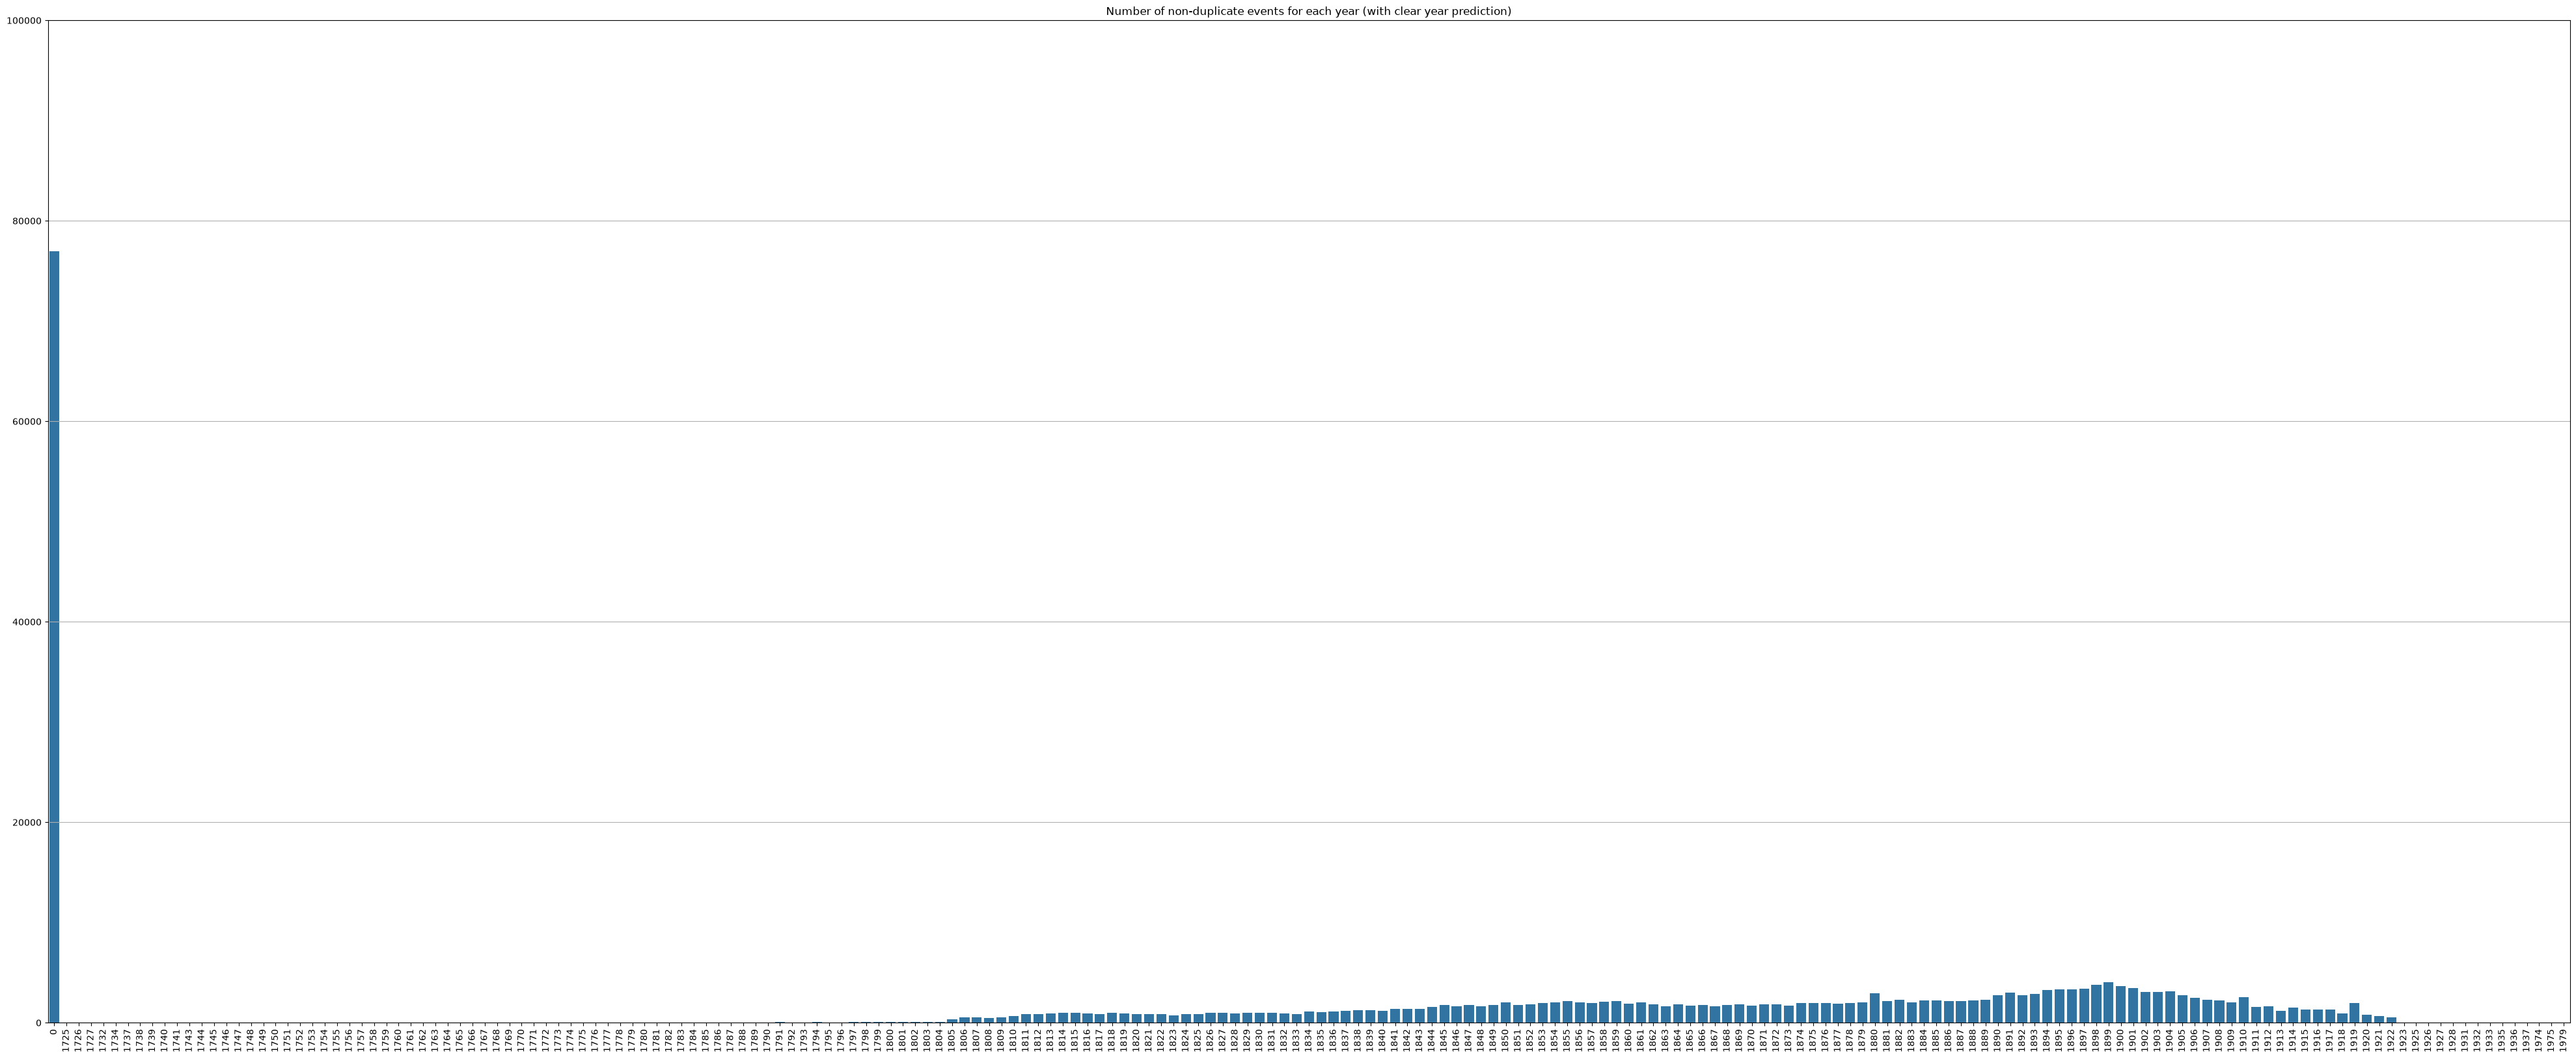

In [24]:
year_start = min(year_counts["all"].keys())
year_end = max(year_counts["all"].keys())

fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in year_counts["all"].items()]),
    y=tuple([x[1] for x in year_counts["all"].items()]),
)
axs.set_ylim(0, 100000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear year prediction)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(year_counts["all"].keys()), rotation=90)

In [25]:
year_start = min(year_counts["all_valid_year"].keys())
year_end = max(year_counts["all_valid_year"].keys())

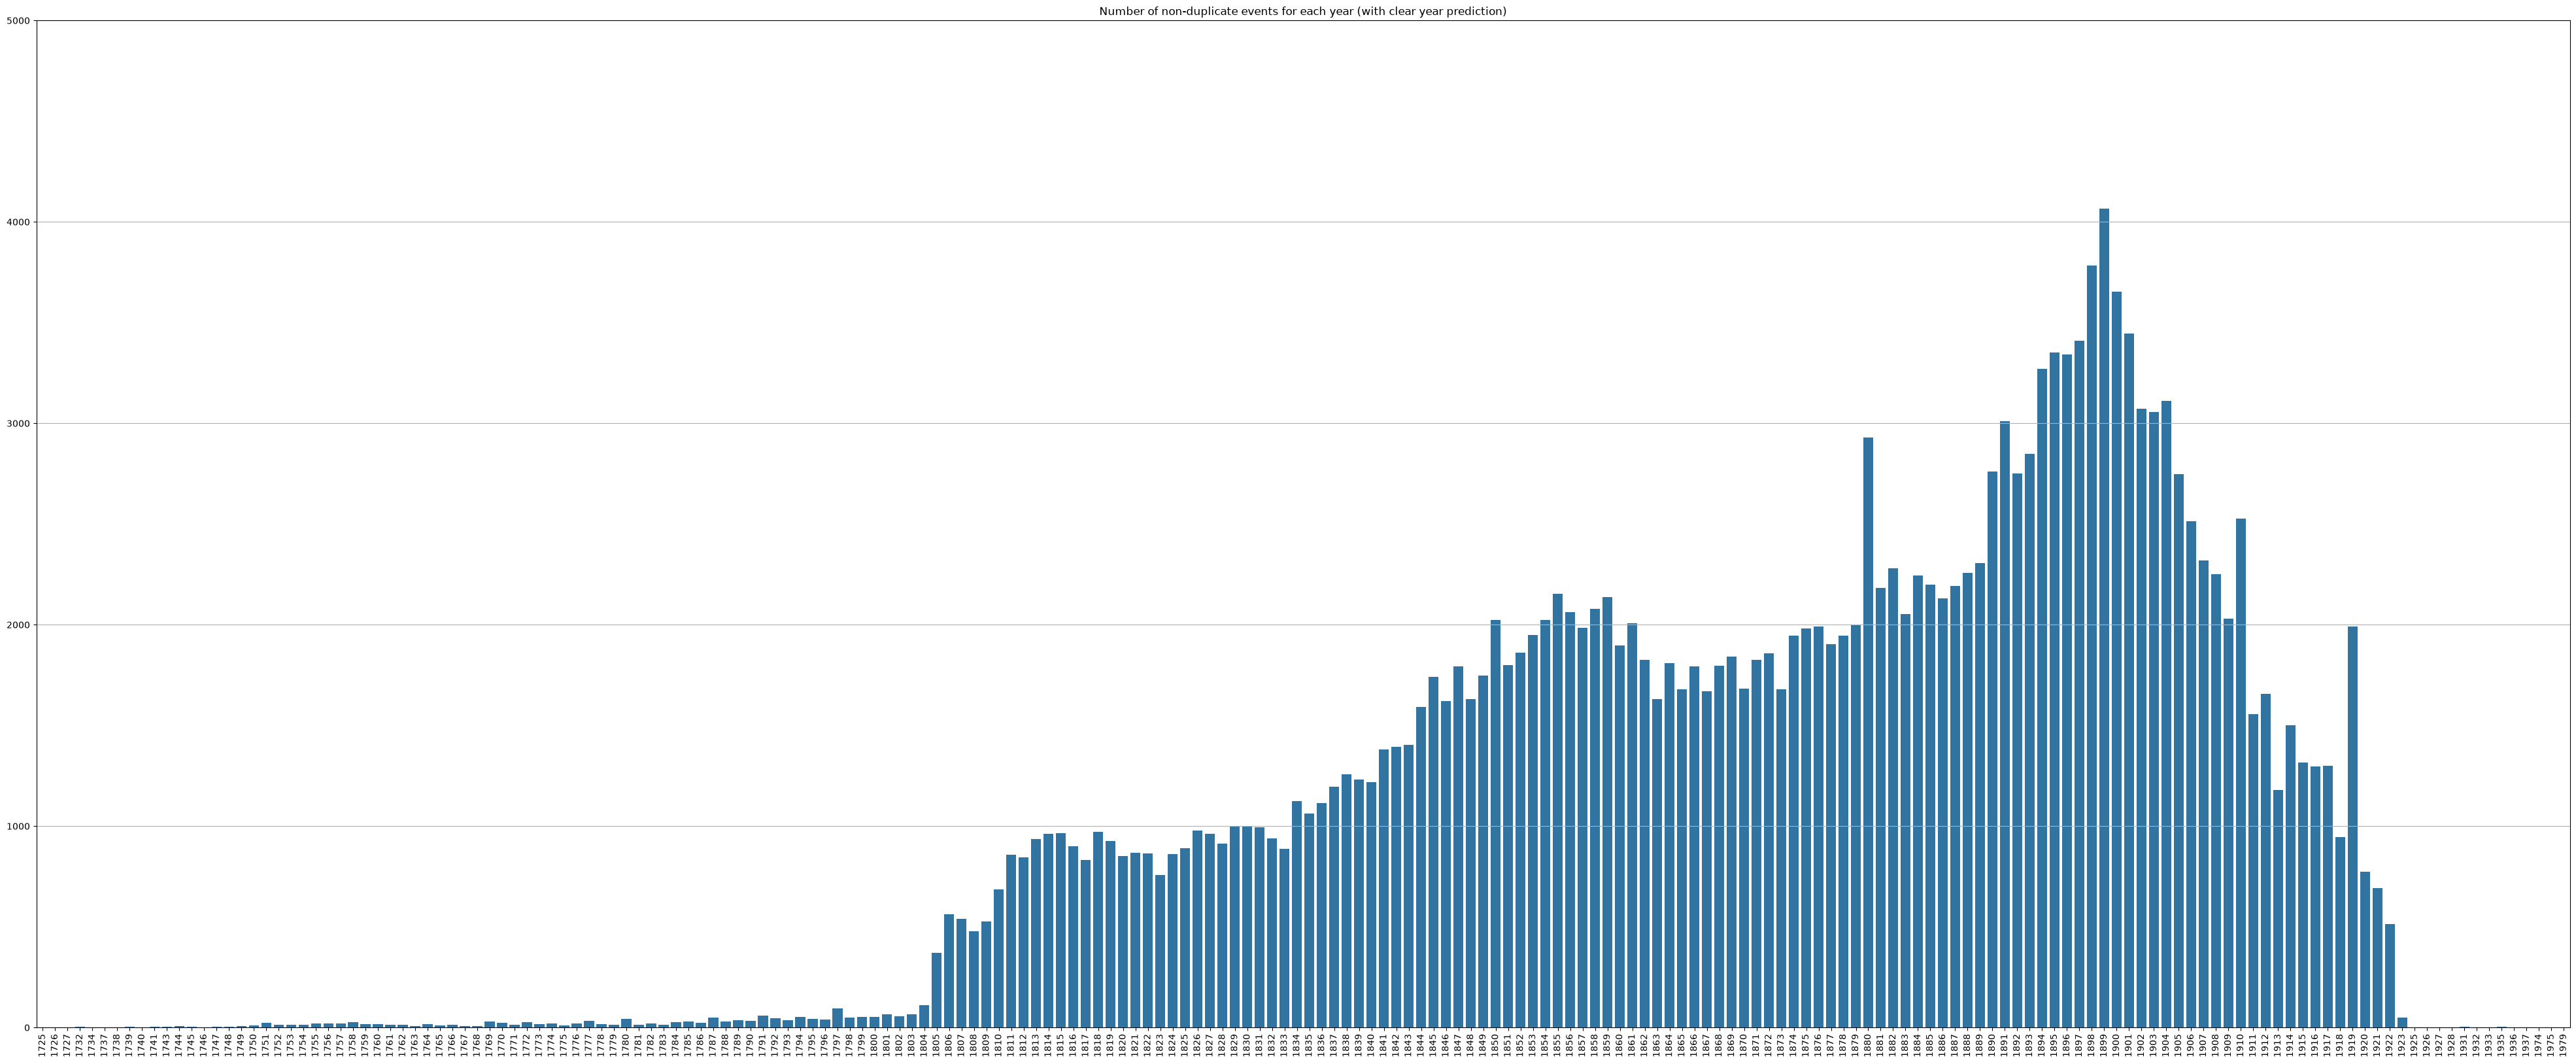

In [26]:
fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in year_counts["all_valid_year"].items()]),
    y=tuple([x[1] for x in year_counts["all_valid_year"].items()]),
)
axs.set_ylim(0, 5000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear year prediction)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(year_counts["all_valid_year"].keys()), rotation=90)

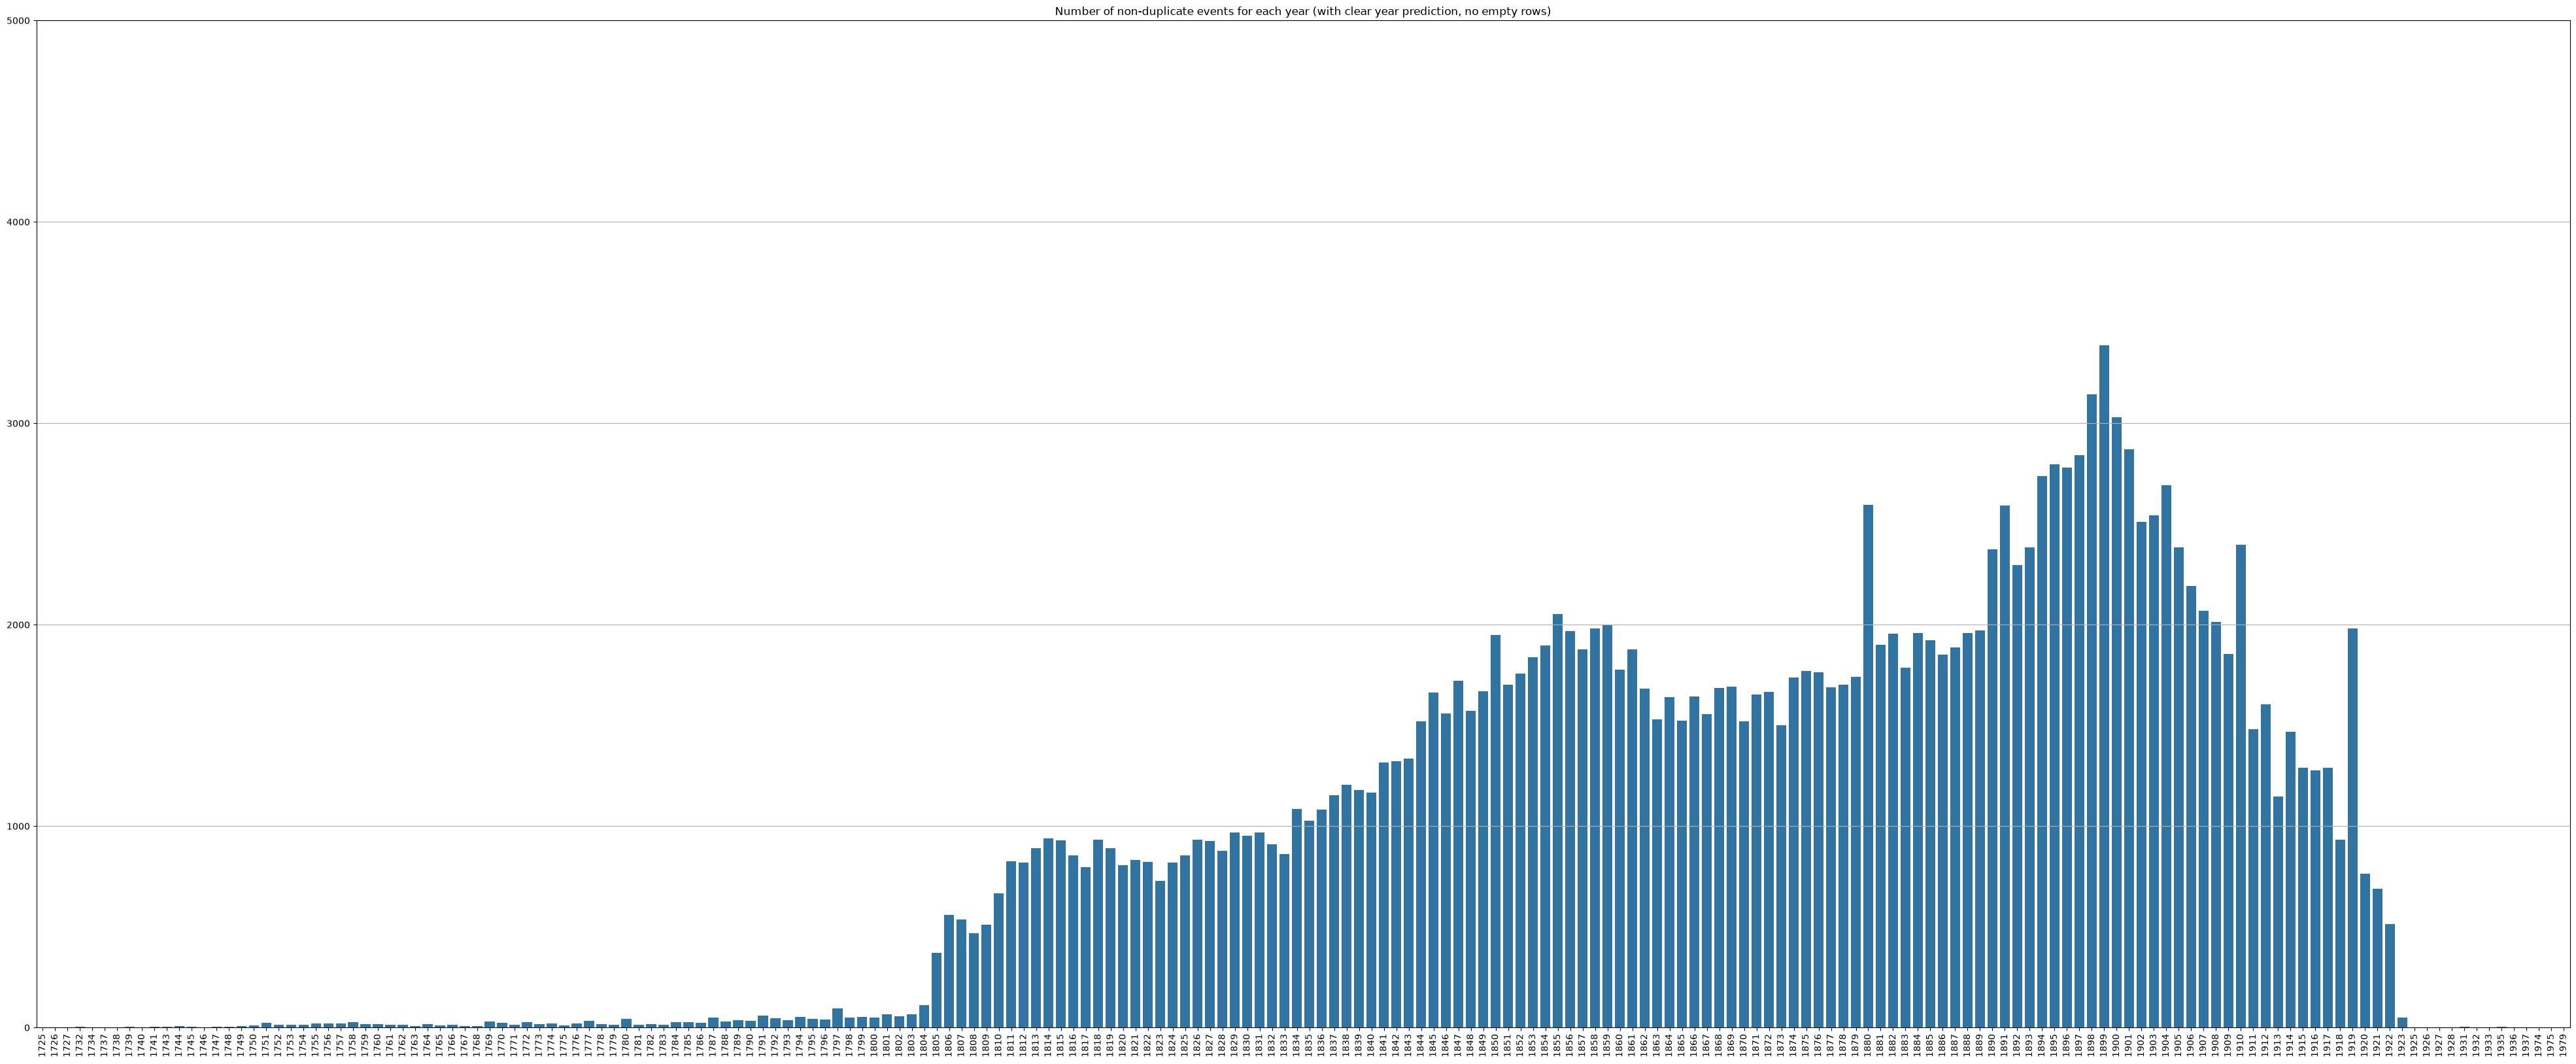

In [27]:
fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in year_counts["non_dup"].items()]),
    y=tuple([x[1] for x in year_counts["non_dup"].items()])
)
axs.set_ylim(0, 5000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear year prediction, no empty rows)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(year_counts["non_dup"].keys()), rotation=90)

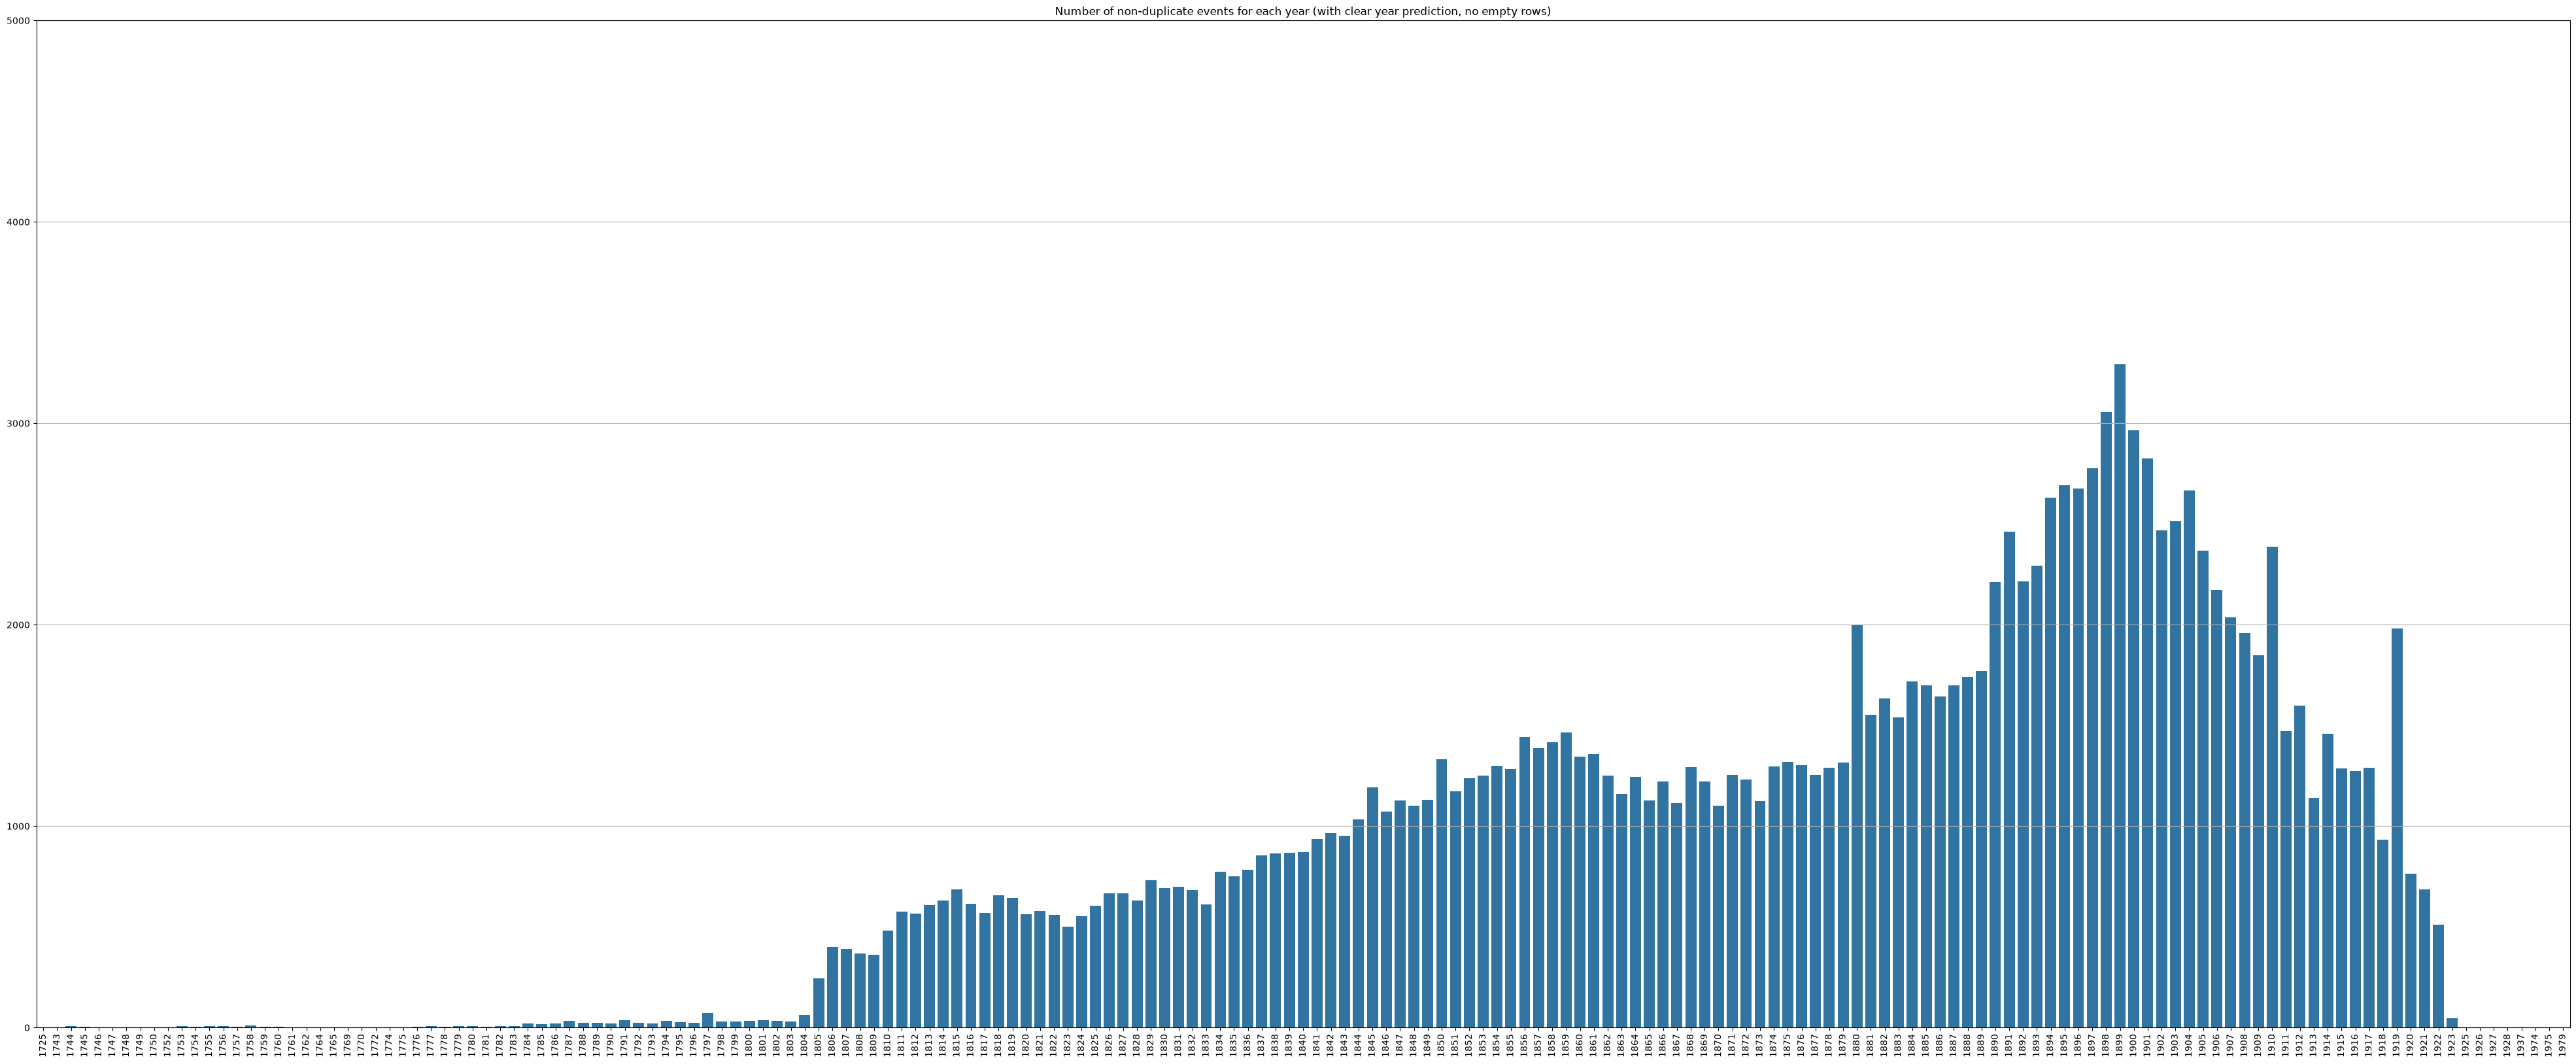

In [28]:
fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in year_counts["non_dup_clear"].items()]),
    y=tuple([x[1] for x in year_counts["non_dup_clear"].items()])
)
axs.set_ylim(0, 5000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear year prediction, no empty rows)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(year_counts["non_dup_clear"].keys()), rotation=90)

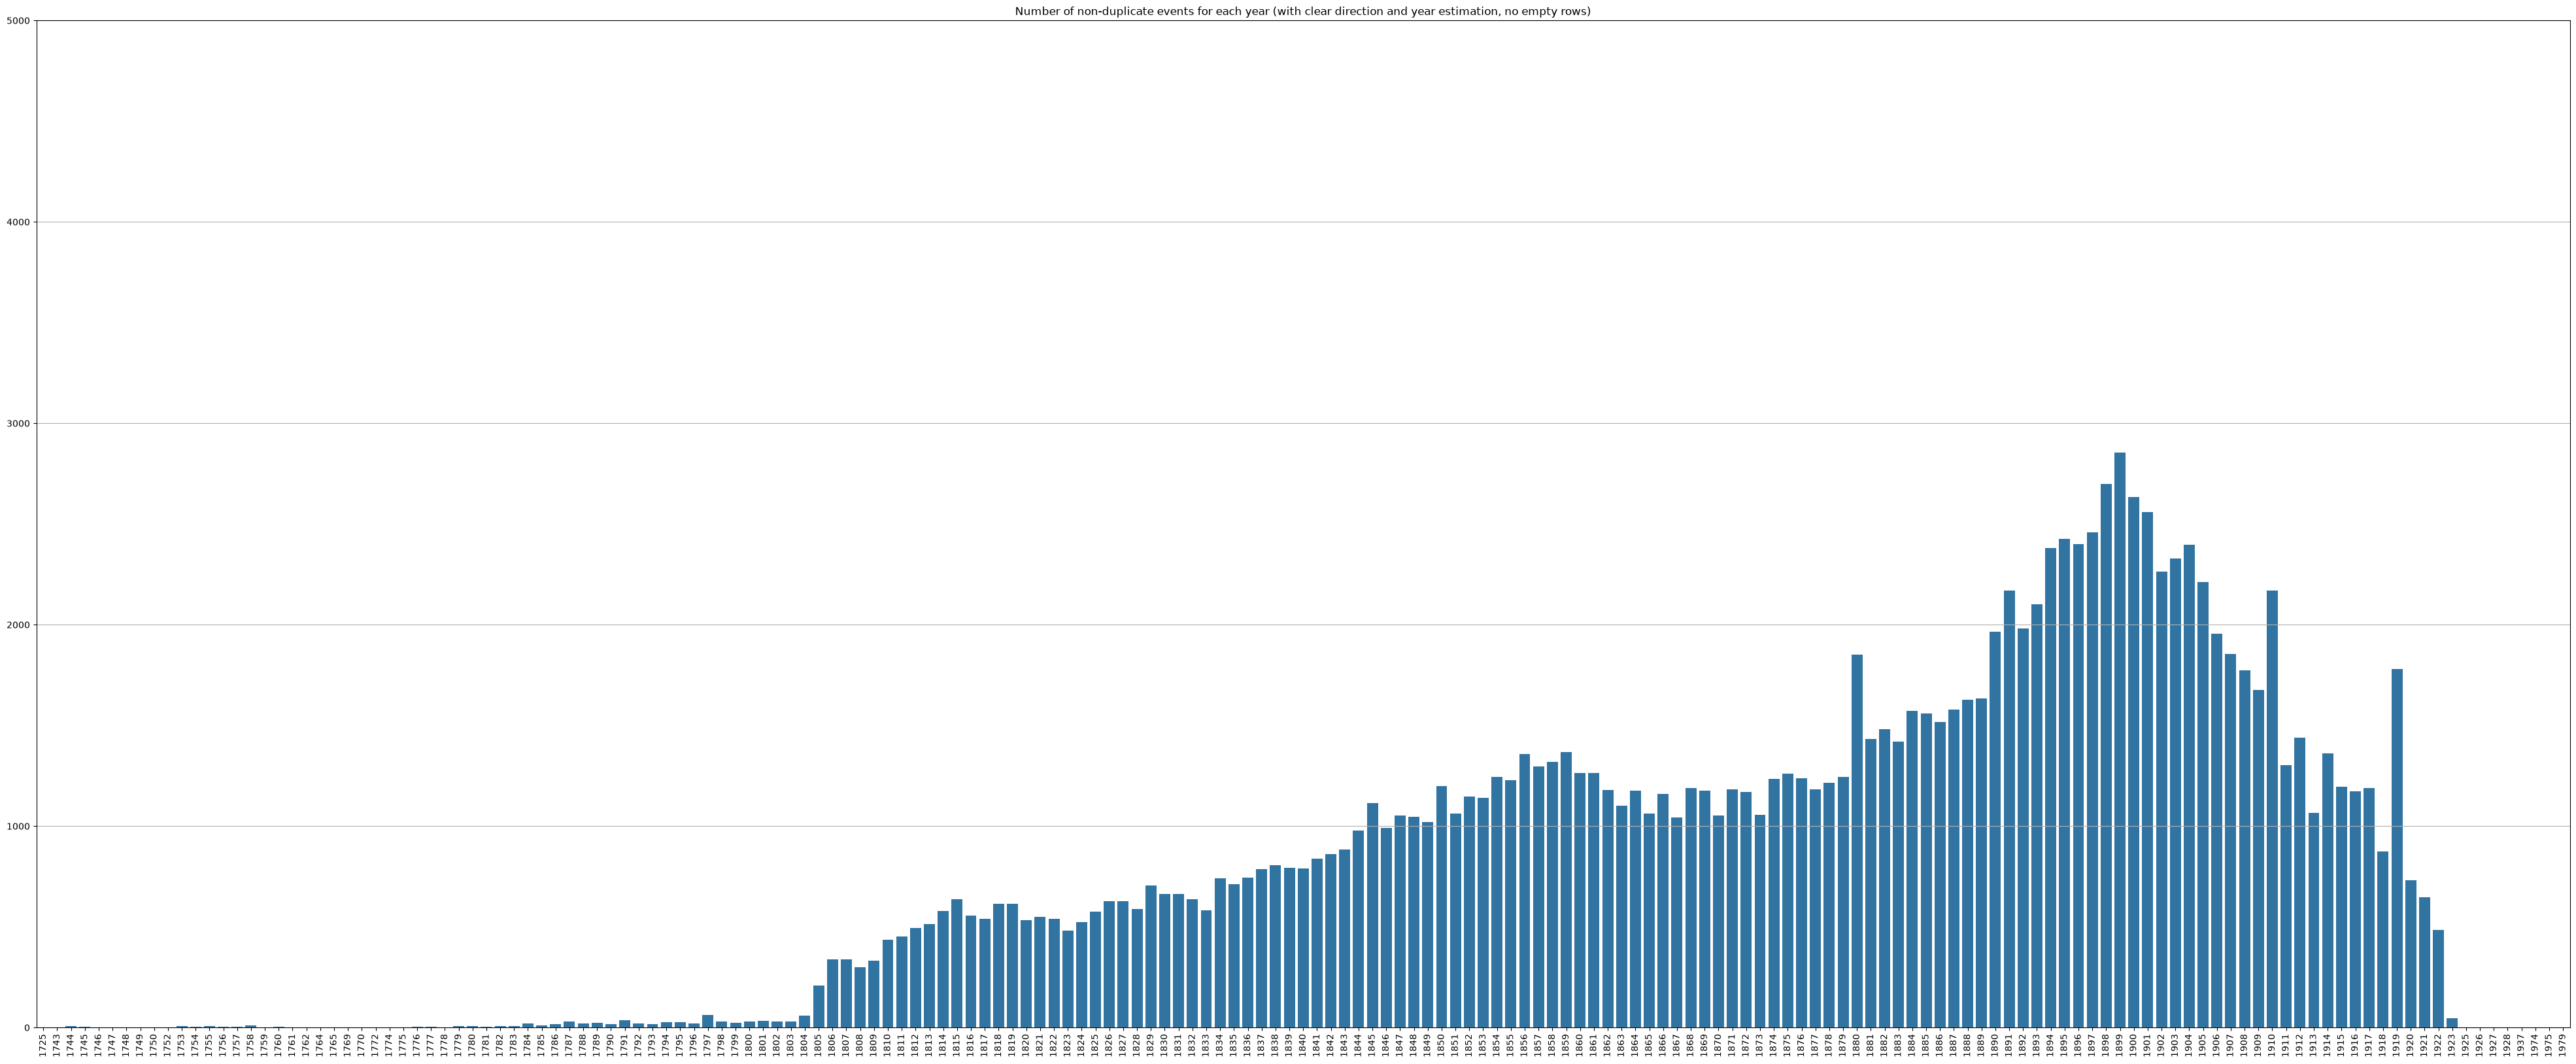

In [29]:
fig, axs = plt.subplots(figsize=(50, 20))
sns.barplot(
    x=tuple([x[0] for x in year_counts["non_dup_clear_info"].items()]),
    y=tuple([x[1] for x in year_counts["non_dup_clear_info"].items()])
)
axs.set_ylim(0, 5000)
axs.grid(axis="y")
axs.set_title("Number of non-duplicate events for each year (with clear direction and year estimation, no empty rows)")
axs.set_xticks(axs.get_xticks())
_ = axs.set_xticklabels(labels=sorted(year_counts["non_dup_clear_info"].keys()), rotation=90)

In [30]:
print(
    f"Pages in total: {counts['total']}",
    f"Pages with fewer than {MIN_INFO_ROWS} informative rows: {counts['total'] - counts['total_info']}",
    f"Total non-duplicate pages: {counts['non_dup']}",
    f"At least {counts['total'] - counts['non_dup']} duplicate pages.",
    f"Total non-duplicate pages with valid year: {sum(year_counts['non_dup'].values())}",
    f"Total non-duplicate pages with clear direction and valid year: {counts['non_dup_clear']}",
    f"At least {round(100 * counts['non_dup_clear'] / counts['non_dup'])}% of non-duplicate pages have unclear direction or year.",
    f"--- Pages with at least {MIN_INFO_ROWS} informative rows ---",
    f"Pages in total: {counts['total_info']}",
    f"Total non-duplicate pages: {counts['non_dup_info']}",
    f"At least {counts['total_info'] - counts['non_dup_info']} duplicate pages.",
    f"Total non-duplicate pages with valid year: {sum(year_counts['non_dup_info'].values())}",
    f"Total non-duplicate pages with clear direction and valid year: {counts['non_dup_clear_info']}",
    f"At least {round(100 * counts['non_dup_clear_info'] / counts['non_dup_info'])}% of non-duplicate pages have unclear direction or year.",
    sep="\n",
)

Pages in total: 283020
Pages with fewer than 5 informative rows: 21086
Total non-duplicate pages: 256410
At least 26610 duplicate pages.
Total non-duplicate pages with valid year: 187125
Total non-duplicate pages with clear direction and valid year: 154667
At least 60% of non-duplicate pages have unclear direction or year.
--- Pages with at least 5 informative rows ---
Pages in total: 261934
Total non-duplicate pages: 235324
At least 26610 duplicate pages.
Total non-duplicate pages with valid year: 171510
Total non-duplicate pages with clear direction and valid year: 142173
At least 60% of non-duplicate pages have unclear direction or year.
